# Mapping mean change in properties at 50 m over the whole Salish Sea

In [23]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import cmocean as cm

plt.rcParams['font.size'] = 12

In [11]:
# bring in data from SalishSeaCast base case (present day)

path='/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results'
files = [f'{path}/map_physics202111_20180101_20221231.nc',f'{path}/map_biology202111_20180101_20221231.nc',f'{path}/map_chemistry202111_20180101_20221231.nc',]

base = xr.open_mfdataset(files)

In [10]:
# bring in data from the different runs

# All 
files = [f'{path}/All_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
all = xr.open_mfdataset(files)

# Local 
files = [f'{path}/Local_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
loc = xr.open_mfdataset(files)

# NorthWest 
files = [f'{path}/NorthWest_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
nor = xr.open_mfdataset(files)

# Salish 
files = [f'{path}/Salish_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
sal = xr.open_mfdataset(files)

# South 
files = [f'{path}/South_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
sou = xr.open_mfdataset(files)

# Up 
files = [f'{path}/Up_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
upw = xr.open_mfdataset(files)

In [98]:
# mapping 
mesh = xr.open_dataset('/home/sallen/MEOPAR/grid/mesh_mask201702.nc')


def changemap(tracer,proj_data,base_data,ax, *, colourbar=False):

    # tracer range lookup table
    levels_dict = {'temp': 1.6, 'salt': 0.5,
                 'do': 11, 'no3': 0.5, 'ta': 9, 'dic': 65}
    name_dict = {'temp': r'Temperature ($^\circ C$)', 'salt': r'Salinity (g kg$^{-1}$)',
                 'do': r'DO ($\mu mol \, kg^{-1}$)', 'no3': r'NO$_3$ ($\mumol \, m^{-3}$)', 
                 'ta': r'TA ($\mumol \, m^{-3}$)', 'dic': r'DIC ($\mumol \, m^{-3}$)'}
    
    # Ensure a symmetric range about zero
    limit = levels_dict[tracer]
    levels = np.linspace(-limit, limit, 50)

    # contour of change
    c = ax.contourf(
        base.gridX, base.gridY, proj_data-base_data, 
        levels=levels,
        cmap=cm.cm.balance, extend='both',antialiased=True,zorder=1,
    )
    if colourbar==True:
        cax = fig.add_axes([0.315, 0.005, 0.4, 0.01])
        fig.colorbar(c, cax=cax, orientation='horizontal',label=name_dict[tracer], ticks=[-limit,0,limit])

    ax.set_xlabel("Model x")
    ax.set_ylabel("Model y")

    # Draw coastline
    ax.contourf(mesh.tmask[0, 23, ...], levels=[-0.01, 0.01], colors='whitesmoke')
    ax.contour(mesh.tmask[0, 0, ...], levels=[-0.01, 0.01], colors='lightgrey') # traditional coastline
    ax.contour(mesh.tmask[0, 23, ...], levels=[-0.01, 0.01], colors='gray') # waterline at indice 23


/tmp/ipykernel_3825459/3842845548.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


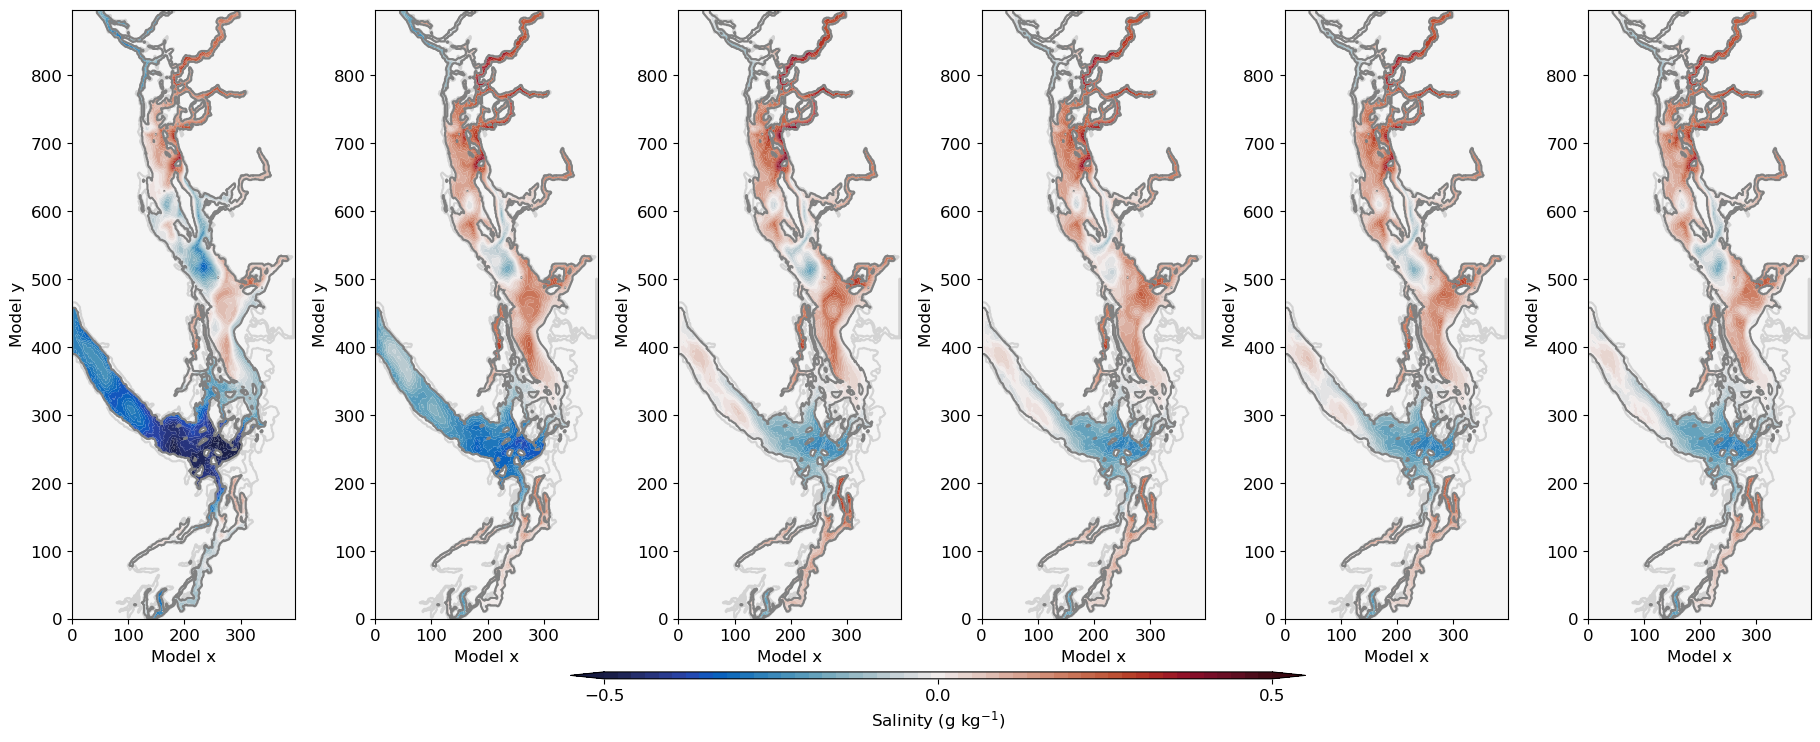

In [99]:
fig, ax= plt.subplots(1,6,figsize=[398/130*6,898/130])

changemap('salt',all.vosaline[0,0,...],base.vosaline[0,0,...],ax[0],colourbar=True)
changemap('salt',loc.vosaline[0,0,...],base.vosaline[0,0,...],ax[1])
changemap('salt',nor.vosaline[0,0,...],base.vosaline[0,0,...],ax[2])
changemap('salt',sal.vosaline[0,0,...],base.vosaline[0,0,...],ax[3])
changemap('salt',sou.vosaline[0,0,...],base.vosaline[0,0,...],ax[4])
changemap('salt',upw.vosaline[0,0,...],base.vosaline[0,0,...],ax[5])

plt.tight_layout()